**Agentic AI** -
**ReAct Agent** - **LangChain**


***Asking LLM about current STOCK MARKET !!!***

In [2]:
from langchain.chat_models import init_chat_model

llm = init_chat_model(model="gpt-5-mini", model_provider="openai", temperature=0.2)
llm.invoke("last 5 days closing prices of NVIDIA").content

'I don’t have live market access, so I can’t fetch current NVDA closing prices. I can, however, show easy ways for you to get the last 5 trading-day closing prices and give sample code you can run.\n\nOptions\n\n1) Quick — Yahoo Finance (web)\n- Go to finance.yahoo.com, search NVDA.\n- Click “Historical Data”, set the date range to the last week or two, click “Apply”, then view “Close” column or click “Download” to get a CSV.\n\n2) Google Sheets\n- Formula to pull recent closes (replace range length if needed):\n  =GOOGLEFINANCE("NASDAQ:NVDA","close",TODAY()-10,TODAY())\n  This returns a date/close table; take the last 5 rows for the last 5 trading days.\n\n3) Python (yfinance)\n- Install: pip install yfinance pandas\n- Example script to print last 5 closing prices:\n  import yfinance as yf\n  import pandas as pd\n  ticker = yf.Ticker("NVDA")\n  hist = ticker.history(period="10d")        # 10 calendar days to ensure 5 trading days\n  print(hist[\'Close\'].tail(5))\n\n- If you prefer ex

***Doing TOOL calls***

In [4]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities.wikipedia import WikipediaAPIWrapper

wiki_tool = WikipediaQueryRun(api_wrapper = WikipediaAPIWrapper(), description="searches wikipedia to get information")
wiki_tool.invoke("NVDIA")

"Page: Nvidia\nSummary: Nvidia Corporation ( en-VID-ee-ə) is an American multinational technology company headquartered in Santa Clara, California. The company develops graphics processing units (GPUs), systems on chips (SoCs), and application programming interfaces (APIs) for gaming, data science, high-performance computing, artificial intelligence (AI) hardware, and mobile and automotive applications. Founded in 1993 by Jensen Huang, Chris Malachowsky, and Curtis Priem, Nvidia is among the largest companies by market capitalization.\nOriginally focused on GPUs for gaming, Nvidia broadened their usage into other markets, including AI, professional visualization, and supercomputing. The company's product lines include GeForce GPUs for gaming and creative workloads, and professional GPUs for edge computing, scientific research, and industrial applications. In 2025, Nvidia became the first company to surpass US$4 trillion and US$5 trillion in market capitalization, largely driven by the 

In [5]:
from langchain_tavily import TavilySearch

web_tool = TavilySearch()

web_tool.invoke("last 5 days closing prices of NVIDIA")

{'query': 'last 5 days closing prices of NVIDIA',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://finance.yahoo.com/quote/NVDA/history',
   'title': 'NVIDIA Corporation (NVDA) Stock Historical Prices & Data - Yahoo Finance',
   'content': '### Chart previous close\n\n| Field | Value |\n --- |\n| Last bar timestamp | 2026-11-19 14:30 UTC |\n\n#### Range\n\n| Field | Value |\n --- |\n| 1d | 150.96 |\n| 5d | 166.19 |\n| 1mo | 217.09 |\n| 3mo | 217.56 |\n| 6mo | 220.61 |\n| 1y | 186.52 |\n| 2y | 147.01 |\n| 5y | 32.985 |\n| 10y | 2.334 |\n| Ytd | 186.5 |\n| Max | 0.044 |\n\n### Calendar events\n\n| Field | Value |\n --- |\n| Ex dividend date | 2026-12-02 |\n| Dividend date | 2026-10-01 |\n\n#### Earnings [...] | 2025-12-08 | 182.64 | 188.00 | 182.40 | 185.55 | 185.12 | 204,378,100 |\n| 2025-12-05 | 183.89 | 184.66 | 180.91 | 182.41 | 181.98 | 143,971,100 |\n| 2025-12-04 | 181.62 | 184.52 | 179.96 | 183.38 | 182.95 | 167,364,900 |\n| 2025-12-03 | 

***Designing own tool***

In [6]:
from langchain.tools import tool
from utils.mail_helper import send_email

@tool
def email_tool(subject: str, to_mail: str, body: str)->str:
    """ This tool sends email to user """
    res = send_email(
        subject=subject,
        to_mail=to_mail,
        body=body
    )
    return res



In [7]:
ToolKit = [ wiki_tool, web_tool, email_tool]
ToolKit


[WikipediaQueryRun(description='searches wikipedia to get information', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\Workspace\\GenAIPractice\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 TavilySearch(api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None)),
 StructuredTool(name='email_tool', description='This tool sends email to user', args_schema=<class 'langchain_core.utils.pydantic.email_tool'>, func=<function email_tool at 0x00000192E78156C0>)]

**Creating own AI Agent**

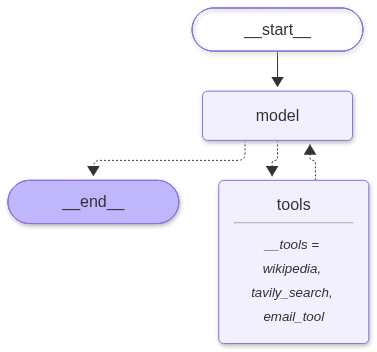

In [8]:
from langchain.agents import create_agent

agent = create_agent(model=llm, tools = ToolKit)
agent

***#1 Way of Streaming the agent***

In [11]:
from langchain_core.prompts import ChatPromptTemplate

receipent_mail = input("enter receipent_mail_id: ")
Name_of_stock = input("enter Name of stock: ")


prompt_template = ChatPromptTemplate.from_messages([
    ("system", "You are gen-z assistant"),
    ("user", "What are last 10 trading days closing prices of {Name_of_stock} ? after send email to receipent {receipent_mail} with subject containing title - {Name_of_stock} Details & the mail body should contain Ticker, Day, Closing Price.")
])

ready_prompt = prompt_template.invoke({"receipent_mail":receipent_mail, "Name_of_stock":Name_of_stock})

ready_prompt

ChatPromptValue(messages=[SystemMessage(content='You are gen-z assistant', additional_kwargs={}, response_metadata={}), HumanMessage(content='What are last 10 trading days closing prices of NATIONALUM ? after send email to receipent venkateshnagumantri11@gmail.com with subject containing title - NATIONALUM Details & the mail body should contain Ticker, Day, Closing Price.', additional_kwargs={}, response_metadata={})])

In [12]:
events = agent.stream(
    ready_prompt,
    stream_mode="values"
)

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

What are last 10 trading days closing prices of NATIONALUM ? after send email to receipent venkateshnagumantri11@gmail.com with subject containing title - NATIONALUM Details & the mail body should contain Ticker, Day, Closing Price.
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_EDQTePCnQ9J0IqFlTBnSlE5j)
 Call ID: call_EDQTePCnQ9J0IqFlTBnSlE5j
  Args:
    query: NATIONALUM historical closing prices last 10 trading days NATIONALUM NSE historical data
    search_depth: advanced
    include_images: False
================================= Tool Message =================================
Name: tavily_search

{"query": "NATIONALUM historical closing prices last 10 trading days NATIONALUM NSE historical data", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://stockanalysis.com/quote/nse/NATIONALUM/history", "t

***#2 way of streaming the agent***
 

In [14]:
events = agent.stream(
    {
        "messages":[
            ('system', 'you are professional assistant'),
            ('human', "Do wiki search about Ashok Leyaland company to know about key details. after list me it's last 10 trading days closing prices in NSE. ")
        ]
    },
    stream_mode="values"
)

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Do wiki search about Ashok Leyaland company to know about key details. after list me it's last 10 trading days closing prices in NSE. 
================================== Ai Message ==================================
Tool Calls:
  wikipedia (call_Q9dkzjm3VI3KD93PNfAZVRd7)
 Call ID: call_Q9dkzjm3VI3KD93PNfAZVRd7
  Args:
    query: Ashok Leyland
================================= Tool Message =================================
Name: wikipedia

Page: Ashok Leyland
Summary: Ashok Leyland Limited is an Indian multinational automotive manufacturer headquartered in Chennai and owned by the Hinduja Group. Founded in 1948 as Ashok Motors, it was renamed Ashok Leyland in 1955 following a collaboration with British Leyland. Today it is the second-largest manufacturer of commercial vehicles in India (holding a 32.1% market share as of 2016), the third-largest bus manufacturer, and the tenth-largest manufacturer of lorri